# 070 CASE 060 — Vegetation edge: the Småland coast

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** Where does vegetation give way to open land and water along the Småland coast?

**Area:** Coastal mosaic of forest, open land and wetland south of Kalmar (Småland), 29 July 2024.

**Partners:** Swedish Forest Agency, Swedish EPA, Stockholm University, RISE

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Copernicus Sentinel-2 data are free and open.

## Before you run

Install IMINT Engine at the commit these results were produced with, plus the plotting libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1a" folium matplotlib
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own
DES account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password. The login is yours: no credentials are shared or saved in the notebook. Without a login the data fetch stops with an error; there is no synthetic
fallback, so every figure comes from real Sentinel-2 data. A run takes about a minute on a laptop CPU.

## Log in to Digital Earth Sweden

In [ ]:
import os
from getpass import getpass

import openeo

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked (never saved in the notebook)
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
if LOGIN_METHOD == "password":
    os.environ["DES_USER"] = input("DES username: ")
    os.environ["DES_PASSWORD"] = getpass("DES password: ")
    des.authenticate_basic(os.environ["DES_USER"], os.environ["DES_PASSWORD"])
else:
    des.authenticate_oidc(provider_id="egi")  # rerun this cell when the session expires


def des_token():
    """Your EGI login's access token; with a password login IMINT Engine reads DES_USER/DES_PASSWORD."""
    return des.auth.bearer.split("/", 2)[2] if LOGIN_METHOD == "egi" else None


## 1. Method

```
AOI + date → fetch_des_data → VegetationEdgeAnalyzer → water / non-vegetated / vegetated map + edge centreline
```

## 2. Area and data

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import folium

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud, token=des_token())
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene

AOI = {"west": 16.30, "south": 56.95, "east": 16.50, "north": 57.05}
DATE = "2024-07-29"

scene = load_scene(DATE, AOI)

    [DES] openEO api=1.1.0 url=https://openeo.digitalearth.se/


    Cloud fraction: 0.1%
2024-07-29: 11 bands, 1139 x 1238 px at 10 m, cloud 0.1% (SCL), CRS EPSG:3006


In [3]:
center = [(AOI["south"] + AOI["north"]) / 2, (AOI["west"] + AOI["east"]) / 2]
m = folium.Map(location=center, zoom_start=11, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satellite basemap",
).add_to(m)
folium.Rectangle(
    bounds=[[AOI["south"], AOI["west"]], [AOI["north"], AOI["east"]]],
    color="#00aa00", weight=2, fill=False, popup="AOI",
).add_to(m)
folium.LayerControl().add_to(m)
m

## 3. Run the vegetation-edge analyzer

In [4]:
from imint.analyzers.vegetation_edge import VegetationEdgeAnalyzer

edge = VegetationEdgeAnalyzer({}).run(rgb=scene.rgb, bands=scene.bands, date=DATE, coords=AOI,
                                      output_dir="outputs/060", scl=scene.scl, geo=scene.geo)
print(edge.summary())
ve = edge.outputs
print(f"vegetated fraction: {ve['vegetation_fraction']:.1%}, edge segments: {ve['n_contours']}")
for name, frac in ve["class_fractions"].items():
    print(f"  {name}: {frac:.1%}")

[vegetation_edge] OK — outputs: segmentation_map, vegetation_edge_mask, vegetation_fraction, class_fractions, ndvi, n_contours
vegetated fraction: 81.8%, edge segments: 261
  water: 13.0%
  non_vegetated: 5.2%
  vegetated: 81.8%


## 4. Results

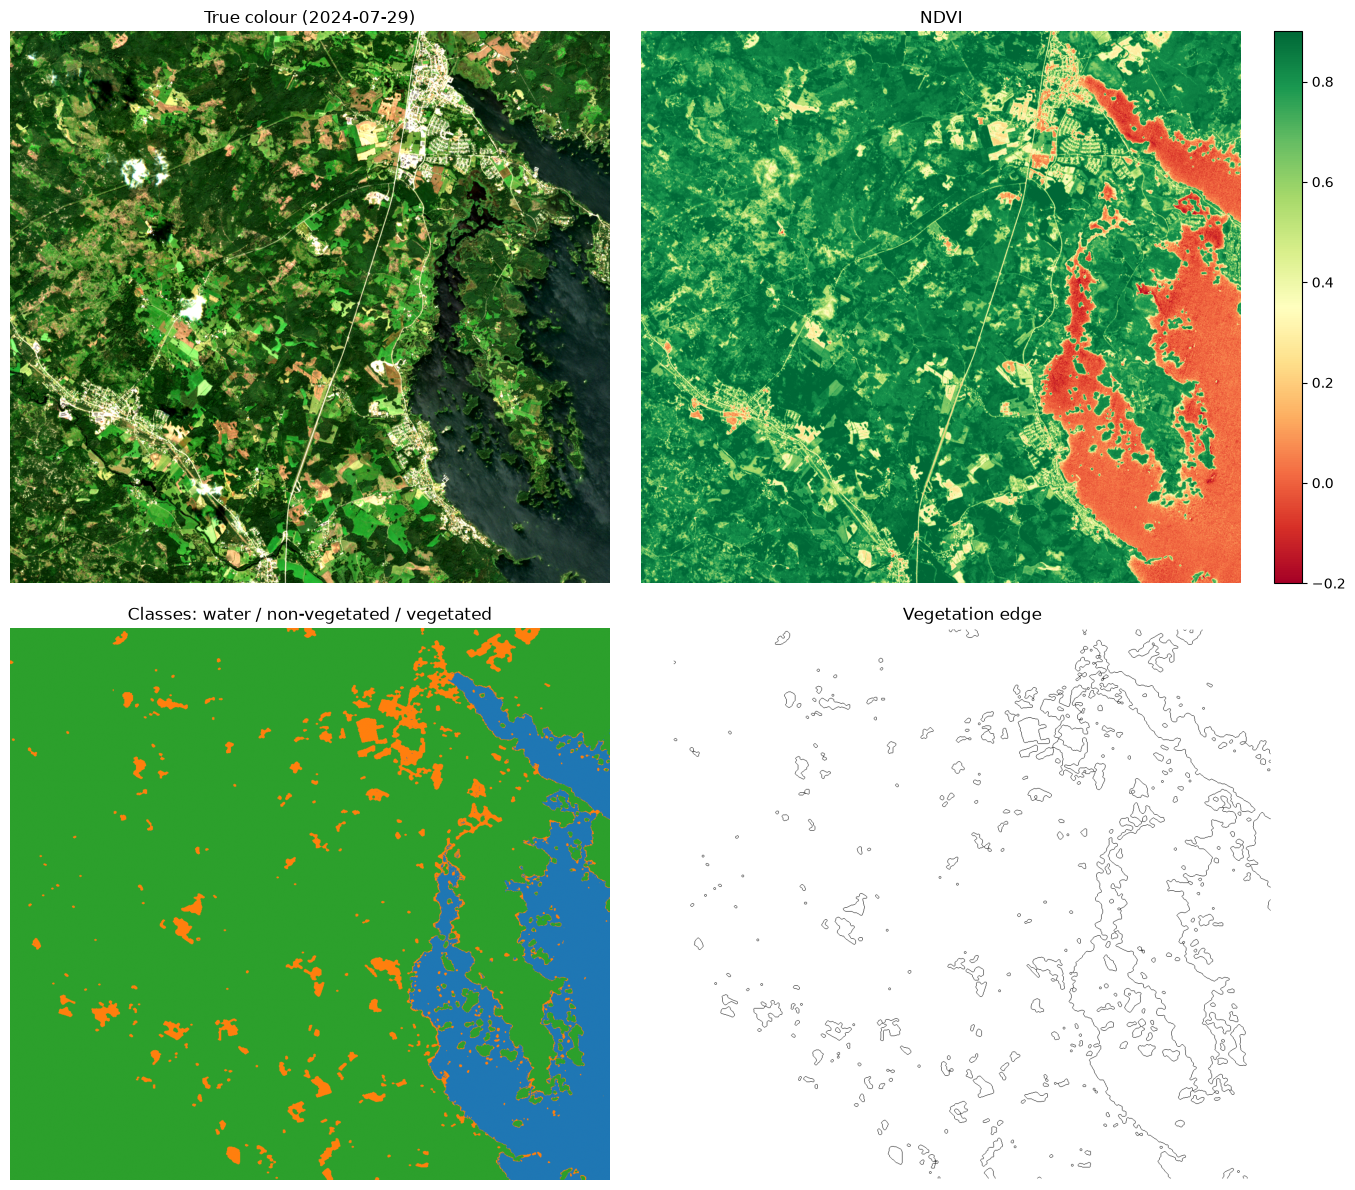

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes[0, 0].imshow(scene.rgb); axes[0, 0].set_title(f"True colour ({DATE})")
im = axes[0, 1].imshow(ve["ndvi"], cmap="RdYlGn", vmin=-0.2, vmax=0.9); axes[0, 1].set_title("NDVI")
fig.colorbar(im, ax=axes[0, 1], fraction=0.046)
axes[1, 0].imshow(ve["segmentation_map"], cmap="tab10", vmin=0, vmax=9)
axes[1, 0].set_title("Classes: water / non-vegetated / vegetated")
axes[1, 1].imshow(ve["vegetation_edge_mask"], cmap="binary"); axes[1, 1].set_title("Vegetation edge")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Interpretation

The edge map follows shorelines, field boundaries and clearings. Compared over several years it can
show overgrowth of open coastal meadows or new clear-cuts; on its own it describes one moment.

**Links:** [`imint/analyzers/vegetation_edge.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers/vegetation_edge.py)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).